# ¡Hola Ariadna!

Mi nombre es Sofia Arboleda, estaré ayudándote a revisar este proyecto para que quede en su mejor versión.

Para simular la dinámica de un ambiente de trabajo, si veo algún error, en primer instancia solo los señalaré, dándote la oportunidad de encontrarlos y corregirlos por tu cuenta. Esto es útil para que te acostumbres a un escenario laboral. En caso de que no puedas resolver la tarea, te daré una información más precisa en la próxima revisión.

Encontrarás mis comentarios más abajo - **por favor, no los muevas, no los modifiques ni los borres**.

¿Cómo funciona esta revisión? Leeré atentamente tu código y te señalaré tus fortalezas y aquellas cosas que podemos mejorar. Los comentarios aparecerán de esta forma:


<div class="alert alert-block alert-success">
<b>Comentario de la revisora</b> <a class="tocSkip"></a>

Si todo está perfecto y no se requieren cambios en el código.
</div>


<div class="alert alert-block alert-warning">
<b>Comentario de la revisora</b> <a class="tocSkip"></a>

Si tu código está bien pero se puede mejorar o hay algún detalle que le hace falta. Se aceptan uno o dos comentarios de este tipo en el borrador, pero si hay más, deberás hacer las correcciones.
</div>

<div class="alert alert-block alert-danger">

<b>Comentario de la revisora</b> <a class="tocSkip"></a>

Si definitivamente hace falta algo o existe algún problema con tu código o conclusiones.
</div>

Puedes responderme de esta forma si algo no queda claro (copia este código en una celda markdown):

<div class="alert alert-block alert-info">
<b>Respuesta del estudiante</b> <a class="tocSkip"></a>

Hola, muchas gracias por tus comentarios y la revisión.        
</div>

# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

### Comentario General Iteración #1
<div class="alert alert-block alert-success">

Ariadna, quería dejarte aquí una apreciación general de tu proyecto para que a partir de allí nos vayamos punto por punto. 

Primero que nada, espero qu este camino en el mundo de los datos esté siendo muy interesante y lleno de aprendizajes significativos. Espero que lo disfrutes y puedas hacerte muchas preguntas que te lleven a analizar y ver los datos como si fueran historias, porque al final, ese es nuestro objetivo!

Respecto a tu trabajo en esta primera iteración, felicitarte porque has mostrado tus conocimientos de la mejor forma, utilizando los metodos correctamente, realizando filtros de forma sencilla y trabajando con los diferentes datasets para llegar a las respuestas de negocio que se buscaban en este proyecto. 

Sigue aprendiendo bastante en este camino, excelente trabajo!
</div>

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [1]:
# Importar librerías
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt


### Cargar Dataset

In [2]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [3]:
# mostrar las primeras 5 filas
df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


<div class="alert alert-block alert-success">
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a>

Buen trabajo con la importación de las librerías y datasets requeridos, al igual que con los métodos para la exploración inicial de los datos.

## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

💡
Después de analizar la información anterior, completa la siguiente sección.  
- Si aplica, señala la o las columnas que requieren algun cambio

Recuerda eliminar este bloque de texto antes de subir el proyecto a tu portafolio.


#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna edad se encuentran en tipo de float64 y deberian estar en int64.


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [4]:
# Corregir el tipo de dato
df['edad'] = df['edad'].astype(int)

In [5]:

# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [6]:
# Estadísticas descriptivas de variables numéricas
df[['edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes', 'gasto_publicidad_dirigida', 'satisfaccion', 'ingreso_anual']].describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,244.690000


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables numéricas

- edad: Distribución simétrica (media y mediana en 38 años), con un rango de usuarios entre 18 y 75 años.

- nivel_ingreso: Distribución muy equilibrada sin sesgos; la media y la mediana son prácticamente idénticas (~30,020).

- visitas_mes: Comportamiento uniforme centrado en 10 visitas mensuales (media y mediana coinciden).

- compras_mes: Valores bajos y concentrados; el 50% de los usuarios realiza 1 o menos compras al mes (máximo de 8).

- gasto_publicidad_dirigida: Distribución balanceada alrededor de 20, con valores que van desde 0 hasta 75.51.

- satisfaccion: Puntuaciones estables en escala de 1 a 5, con media y mediana exactamente en 3.6.

- ingreso_anual: Presenta un sesgo a la derecha y posibles valores atípicos; la media (36.59) supera a la mediana (30.70) y alcanza un máximo muy lejano de 244.69.
 

#### Explorar variables binarias

In [7]:
# Verificar que cada columna tenga únicamente dos valores posibles
df[['miembro_premium', 'abandono']].apply(pd.Series.value_counts)

,miembro_premium,abandono
0,12911,12739
1,2089,2261


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables binarias

- `miembro_premium`: Predominan los usuarios no suscritos; 12,911 clientes no tienen membresía premium, mientras que solo 2,089 clientes cuentan con ella.
  
- `abandono`: Muestra una tasa de pérdida baja; 12,739 usuarios continúan activos en la plataforma frente a 2,261 usuarios que abandonaron el servicio.

#### Explorar variables categóricas

In [8]:
# Verificar el número de valores únicos por variable categórica
df[['tipo_dispositivo', 'region']].apply(pd.Series.describe)

,tipo_dispositivo,region
count,15000,15000
unique,3,4
top,móvil,norte
freq,9818,4395


In [9]:
# Explorar variables categóricas y cómo se distribuyen
variables_categoricas = ['tipo_dispositivo', 'region']
for variables in variables_categoricas:
    print(variables)
    print(df[variables].value_counts(normalize=True))
    print()

tipo_dispositivo
móvil         0.654533
escritorio    0.248000
tablet        0.097467
Name: tipo_dispositivo, dtype: float64

region
norte    0.2930
oeste    0.2540
sur      0.2484
este     0.2046
Name: region, dtype: float64



✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables categóricas

- `tipo_dispositivo`: Muestra una marcada concentración en el acceso móvil (65.5%), seguido por el uso en escritorio (24.8%) y, en una proporción menor, el uso de tablet (9.7%).
- `region`: Presenta una distribución relativamente uniforme entre zonas (20% - 29%), liderada por la región Norte (29.3%), seguida de Oeste (25.4%), Sur (24.8%) y Este (20.5%).

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

<div class="alert alert-block alert-success">
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a>

Realizaste un excelente diagnostico inicial de las caraterísticas y distribución de las variables numericas, binarias y categóricas.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

<function matplotlib.pyplot.show(close=None, block=None)>

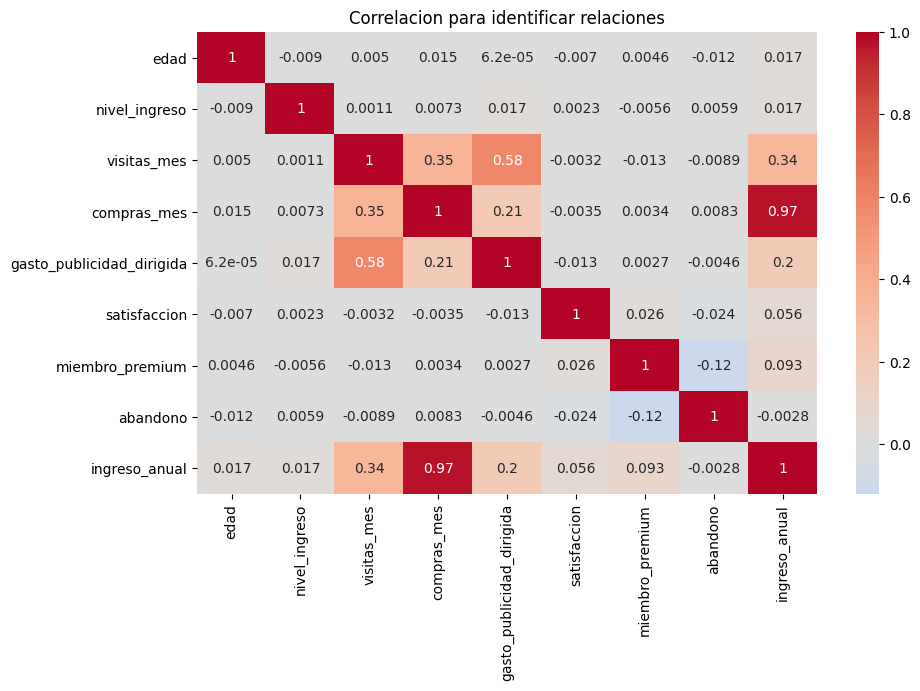

In [10]:
# Visualizar la matriz de correlación para identificar relaciones
corr = df.corr()
plt.figure(figsize = (10,6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0)
plt.title("Correlacion para identificar relaciones")
plt.show

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves


Observaciones generales (Heatmap)  
Se observa:
- Una tendencia entre publicidad y visitas (0.58): Se observa una asociación positiva moderada-alta entre gasto_publicidad_dirigida y visitas_mes, indicando que un mayor gasto publicitario tiende a coincidir con un mayor número de visitas.
  
- Una relación moderada entre visitas y compras (0.35): Existe un patrón positivo entre visitas_mes y compras_mes, donde un incremento en el visitas por usuario suele acompañar un mayor número de compras.

- Las variables como edad, nivel_ingreso y satisfaccion presentan coeficientes cercanos a cero entre sí y con el resto de métricas, lo que sugiere una ausencia de patrones lineales en estos factores.

Observaciones respecto a `ingreso_anual`  
Presenta:
- Una fuerte asociación lineal con compras_mes (0.97): Es la relación más estrecha del análisis; los datos muestran que la frecuencia de compras se mueve casi a la par con la generación de ingresos anuales.

- Asociación moderada a leve con la actividad digital: Se aprecia que visitas_mes (0.34) y gasto_publicidad_dirigida (0.20) acompañan de forma positiva al ingreso_anual, sugiriendo que la interacción con la plataforma está alineada con el valor del cliente, sin que esto implique una relación de causalidad directa.

- Factores como edad (0.017), nivel_ingreso (0.017) o satisfaccion (0.056) no exhiben una tendencia lineal respecto a la variable foco.


### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
  - Genera el gráfico.
  - Describe brevemente qué patrones o tendencias observas.

- **Si decides no incluirlo**:
  - Explica por qué.

### Scatterplot para pares clave

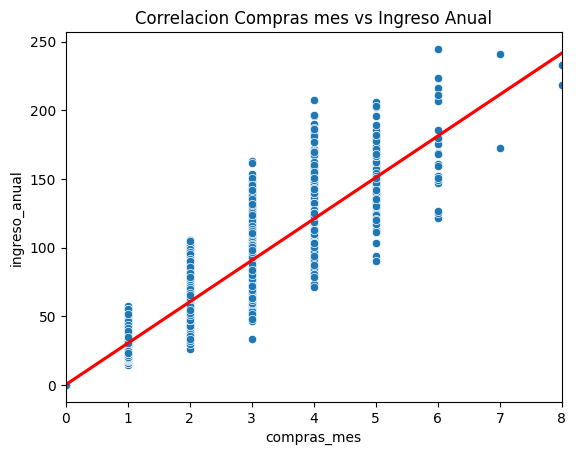

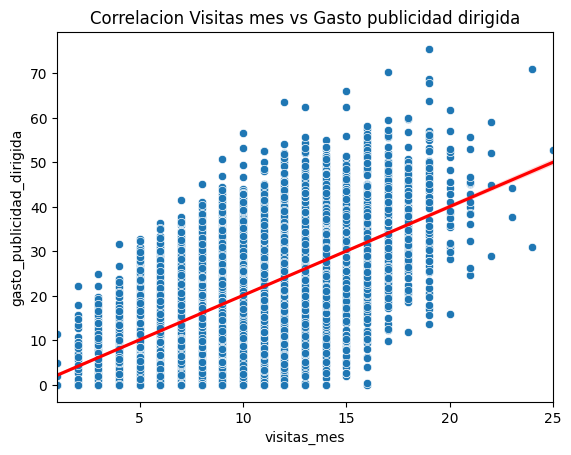

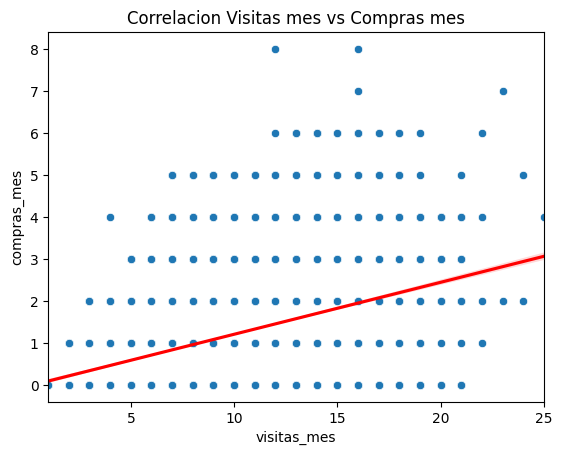

In [11]:
# Visualizar pares de variables con relaciones moderadas o fuertes
sns.scatterplot(data=df, x='compras_mes', y='ingreso_anual')
sns.regplot(data=df, x='compras_mes', y='ingreso_anual', scatter=False, color='red')
plt.title("Correlacion Compras mes vs Ingreso Anual")
plt.show()

sns.scatterplot(data=df, x='visitas_mes', y='gasto_publicidad_dirigida')
sns.regplot(data=df, x='visitas_mes', y='gasto_publicidad_dirigida', scatter=False, color='red')
plt.title("Correlacion Visitas mes vs Gasto publicidad dirigida")
plt.show()

sns.scatterplot(data=df, x='visitas_mes', y='compras_mes')
sns.regplot(data=df, x='visitas_mes', y='compras_mes', scatter=False, color='red')
plt.title("Correlacion Visitas mes vs Compras mes")
plt.show()

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), dispersión (alta, media, baja), presencia de outliers y posible colinealidad.


Observaciones iniciales (Scatterplot)

**Compras mes vs Ingreso anual**
- Dirección: Positiva fuerte.
- Dispersión: Baja; los puntos se agrupan ascendentemente.
- Outliers: No se observan valores atípicos.
- Colinealidad: Alta. Existe un riesgo significativo de multicolinealidad (0.97), indicando que ambas variables aportan información casi idéntica.

**Visitas mes vs Gasto publicidad dirigida**
- Dirección: Positiva moderada.
- Dispersión: Media; los puntos muestran una amplitud moderada a lo largo de la línea de tendencia.
- Outliers: Se observan algunos puntos aislados en valores altos de gasto publicitario (> 70), pero no distorsionan la tendencia general.
- Colinealidad: Baja a moderada (0.58). No representa un riesgo crítico de redundancia para un modelo.

**Visitas mes vs Compras mes**
- Dirección: Positiva débil.
- Dispersión: Alta; los datos se distribuyen ampliamente en franjas horizontales debido al número de compras.
- Outliers: No se identifican atípicos atípicos claros.
- Colinealidad: Nula  (0.35). Las variables son independientes y no generan problemas de colinealidad.

<div class="alert alert-block alert-success">
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a>

Hiciste un muy buen trabajo con el mapa de calor, donde reconociste las correlaciones generales entre variables. El analisis de pares clave también está muy correcto, la elección de `compras_mes` vs `ingreso_anual` y `visitas_mes` y `gato_publicidad_dirigida` es muy valiosa, como mencionas sobre estas relaciones, vale la pena revisar para entender como pueden influir en publicidad, satisfacción y otros factores.  

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [12]:
# Calcular correlación entre variables relevantes
df['compras_mes'].corr(df['ingreso_anual'], method='pearson')

0.9671485435708564

In [13]:
# Calcular correlación entre variables relevantes
df['visitas_mes'].corr(df['gasto_publicidad_dirigida'], method='spearman')

0.5592673242622609

In [14]:
# Calcular correlación entre variables relevantes
df['visitas_mes'].corr(df['compras_mes'], method='pearson')

0.3538438947198978

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves: dirección, magnitud y posible colinealidad.


Observaciones de correlación

**Compras mes vs Ingreso anual**
- Correlación de aproximadamente 1 dando una relacion fuerte positiva. 

**Visitas mes vs Gasto publicidad dirigida**
- Correlación de 0.56 dando una relacion moderada positiva.

**Visitas mes vs Compras mes**
- Correlación de 0.35 dando una relacion debil positiva 

### Punto-biserial

In [15]:
# Calcular correlación entre variables relevantes
from scipy.stats import pointbiserialr
premium = pointbiserialr(df['miembro_premium'], df['ingreso_anual'])
abandono = pointbiserialr(df['abandono'], df['ingreso_anual'])

print("Miembro premium vs Ingreso anual:", premium)
print()
print("Abandono vs Ingreso anual:", abandono)

Miembro premium vs Ingreso anual: SignificanceResult(statistic=0.0930994396198015, pvalue=3.0943076155242597e-30)

Abandono vs Ingreso anual: SignificanceResult(statistic=-0.002823934021617148, pvalue=0.7294691719078393)


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), magnitud (alta, media, baja).

Observaciones Punto-biserial

**Miembro premium vs. Ingreso**
- Tiene una relacion debil o casi nula con un coeficiente de 0.093 pero con direccion positiva.

**Abandono vs. Ingreso anual**
- No tiene una relación ya que el coeficiente es negativo y muy bajo de -0.003.

### V de Cramér

In [16]:
# Función para calcular V de Cramér
from scipy.stats import chi2_contingency
def cramer_v (df, col1, col2):
    tabla = pd.crosstab(df[col1], df[col2])
    chi2, p_value, dof, expected= chi2_contingency(tabla)
    n = tabla.values.sum()
    v = np.sqrt(chi2 / (n *(min(tabla.shape)-1)))
    return v

In [17]:
# Aplicar V de Cramér en variables relevantes
tabla = pd.crosstab(
    df['miembro_premium'],
    df['abandono']
)
tabla 
chi2, p_value, dof, expected= chi2_contingency(tabla)
n = tabla.values.sum()
cramers_v = np.sqrt(chi2 / (n *(min(tabla.shape)-1)))
cramers_v

0.12021874609740511

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.
Incluye qué ves

Se observa que entre miembro premium y abandono; tiene una relacion debil.

Observaciones V de Cramér

<div class="alert alert-block alert-success">
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a>

Muy buen calculo de los diferentes coeficientes para entender la asociacion entre categorías. 


## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

### Hallazgo 1 — Compras_mes vs Ingreso anual

**Evidencia visual:**  
El scatterplot entre compras_mes vs ingreso anual, mostro puntos alineados estrechamente a lo largo de la línea de tendencia ascendente.

**Evidencia numérica:** 
El coeficiente de pearson fue de 0.96. 

**Interpretación**  
Existe una correlación positiva muy fuerte. A mayor número de compras mensuales, mayor es el ingreso anual registrado por el cliente.

**No podemos afirmar**  
Que una variable sea causa directa de la otra (causalidad).

**Implicación de negocio**  
Las estrategias centradas en aumentar la frecuencia de compra impulsan directamente la facturación. Para futuros modelos, se debe seleccionar solo una de estas dos variables para evitar redundancia.

### Hallazgo 2 — Visitas mes vs Gasto publicidad dirigida

**Evidencia visual:**  
El scatterplot entre visitas mes vs gasto publicidad dirigida, mostro una nube de puntos con dispersión moderada y una inclinación hacia arriba.
**Evidencia numérica:** 
El coeficiente de spearman fue de 0.56.
**Interpretación**  
Existe una relación positiva moderada; los registros con mayor gasto en publicidad dirigida suelen estar acompañados por un mayor número de visitas al mes.

**No podemos afirmar**  
Que la publicidad dirigida sea la causa única o directa que genera el tráfico hacia la plataforma.

**Implicación de negocio**  
La inversión publicitaria acompaña bien el nivel de visitas en la plataforma, por lo que conviene mantener estas campañas.

<div class="alert alert-block alert-success">
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a>

Excelente trabajo. Los hallazgos se encuentran bien estructurados y justificados en las cifras exactas obtenidas a lo largo del notebook. 

## Sección 6 - Limitaciones y próximos pasos

### **Limitaciones**
- Correlación ≠ causalidad: Los análisis de Pearson, Spearman, punto biserial y V de Cramér solo revelan si dos variables se mueven juntas, pero no prueban que una cause el comportamiento de la otra.
- Presencia de colinealidad: compras_mes e ingreso_anual presentan una correlación extremadamente alta, lo que duplica información y exige descartar una en fases posteriores.
- Datos atípicos: La muestra no permite explicar a fondo por qué un gran volumen de visitas no se convierte en compras reales.

### **Próximos pasos** 

Probar segmentación adicional
- Analizar el comportamiento de los clientes por tipo de dispositivo (móvil, escritorio, tablet) para identificar si las fallas de conversión ocurren en una plataforma específica.
- Agrupar a los usuarios según su estado de suscripción (miembro_premium vs. usuario estándar) para evaluar patrones.

[Paso 2]
- Eliminar una de las dos variables altamente correlacionadas (como ingreso_anual o compras_mes) antes de entrenar un modelo predictivo para mantener el modelo estable.
[Paso 3]
- Investigar a fondo la baja correlación entre visitas_mes y compras_mes, para corregir fricciones en el proceso de compra.

<div class="alert alert-block alert-success">
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a>

Excelente! Las segmentaciones y revisiones que propones como pasos a futuro para completar este desarrollo son muy utiles, como la implementación de modelos predictivos y la investigación de variables de interés.

Sigue trabajando así!